
## Experiment 1 — Scaling & Temperature Experiment

=== BẢNG THỰC NGHIỆM TEMPERATURE & ENTROPY ===
 Temperature  Max weight  Entropy (bits)                                   Nhận xét
         0.5      0.8668          0.6363 Tập trung cao (Sharp/Peaked), giảm entropy
         1.0      0.6652          1.2009                         Softmax tiêu chuẩn
         2.0      0.5065          1.4718      Phẳng hơn (Smooth/Flat), tăng entropy


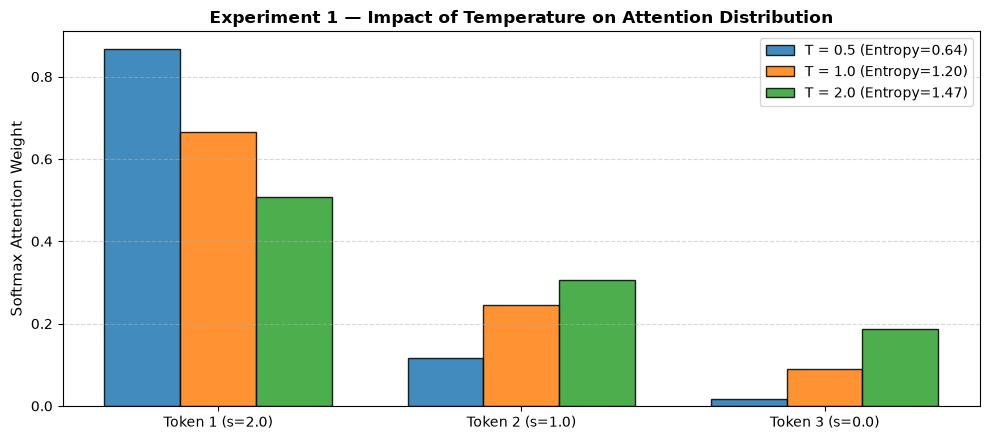

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def stable_softmax(x, axis=-1):
    x_max = np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x - x_max)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

def compute_entropy(probs, eps=1e-12):
    probs = np.clip(probs, eps, 1.0)
    return -np.sum(probs * np.log2(probs))

# Vector điểm số kiểm thử (từ bài tập 14 & 15: s = [2.0, 1.0, 0.0])
scores = np.array([2.0, 1.0, 0.0])
temperatures = [0.5, 1.0, 2.0]

results_temp = []
dist_dict = {}

for T in temperatures:
    scaled_s = scores / T
    probs = stable_softmax(scaled_s)
    dist_dict[f"T={T}"] = probs
    max_w = np.max(probs)
    ent = compute_entropy(probs)
    
    if T < 1.0:
        comment = "Tập trung cao (Sharp/Peaked), giảm entropy"
    elif T == 1.0:
        comment = "Softmax tiêu chuẩn"
    else:
        comment = "Phẳng hơn (Smooth/Flat), tăng entropy"
        
    results_temp.append({
        "Temperature": T,
        "Max weight": np.round(max_w, 4),
        "Entropy (bits)": np.round(ent, 4),
        "Nhận xét": comment
    })

df_temp = pd.DataFrame(results_temp)
print("=== BẢNG THỰC NGHIỆM TEMPERATURE & ENTROPY ===")
print(df_temp.to_string(index=False))

# Trực quan hóa ảnh hưởng của Temperature
x = np.arange(len(scores))
tokens_label = [f"Token 1 (s={scores[0]})", f"Token 2 (s={scores[1]})", f"Token 3 (s={scores[2]})"]
width = 0.25

fig, ax = plt.subplots(figsize=(10, 4.5))
for idx, T in enumerate(temperatures):
    probs = dist_dict[f"T={T}"]
    offset = (idx - 1) * width
    ax.bar(x + offset, probs, width, label=f"T = {T} (Entropy={compute_entropy(probs):.2f})", edgecolor='black', alpha=0.85)

ax.set_ylabel("Softmax Attention Weight", fontsize=11)
ax.set_title("Experiment 1 — Impact of Temperature on Attention Distribution", fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(tokens_label, fontsize=10)
ax.legend(fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## Experiment 2 — Attention Distribution & Query Changing

=== SO SÁNH PHÂN PHỐI ATTENTION GIỮA 2 QUERY ===
       Token  Query A (Sentiment)  Query B (Topic)
         The               0.0151           0.0089
       movie               0.0371           0.6560
         was               0.0167           0.0089
surprisingly               0.1664           0.0098
        good               0.6104           0.0120
     despite               0.0304           0.0098
           a               0.0151           0.0081
        very               0.0410           0.0089
        slow               0.0453           0.0109
   beginning               0.0225           0.2667


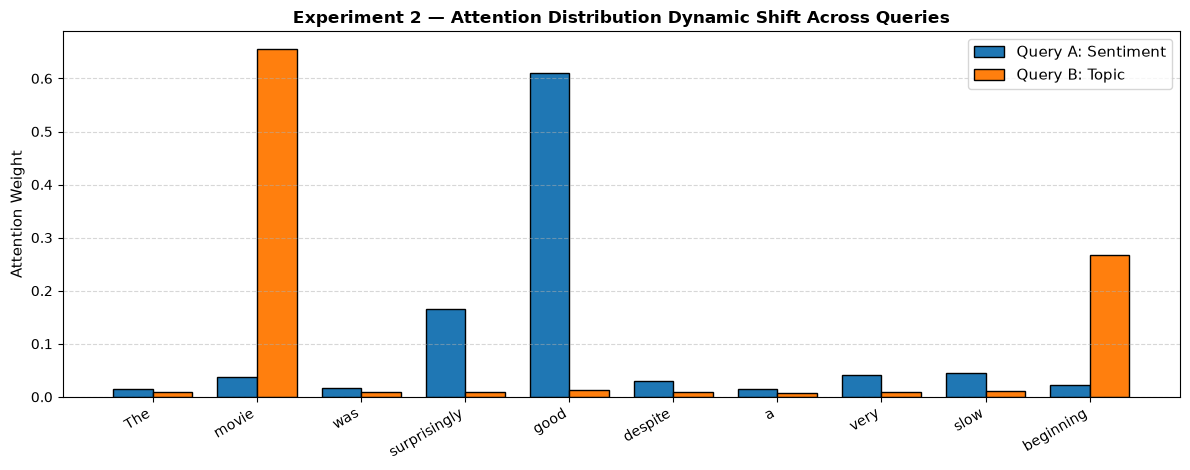

In [2]:
# Chuỗi văn bản thử nghiệm
sequence = "The movie was surprisingly good despite a very slow beginning."
tokens = sequence.replace(".", "").split()

# 1. Query A: Tìm kiếm Sentiment (từ cảm xúc được ưu tiên)
sentiment_scores = np.array([0.1, 1.0, 0.2, 2.5, 3.8, 0.8, 0.1, 1.1, 1.2, 0.5])
attn_sentiment = stable_softmax(sentiment_scores)

# 2. Query B: Tìm kiếm Topic (từ khóa chủ đề được ưu tiên)
topic_scores = np.array([0.2, 4.5, 0.2, 0.3, 0.5, 0.3, 0.1, 0.2, 0.4, 3.6])
attn_topic = stable_softmax(topic_scores)

df_queries = pd.DataFrame({
    "Token": tokens,
    "Score A": sentiment_scores,
    "Query A (Sentiment)": np.round(attn_sentiment, 4),
    "Score B": topic_scores,
    "Query B (Topic)": np.round(attn_topic, 4)
})
print("=== SO SÁNH PHÂN PHỐI ATTENTION GIỮA 2 QUERY ===")
print(df_queries[["Token", "Query A (Sentiment)", "Query B (Topic)"]].to_string(index=False))

# Vẽ biểu đồ so sánh cạnh nhau
x = np.arange(len(tokens))
width = 0.38

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.bar(x - width/2, attn_sentiment, width, label='Query A: Sentiment', color='#1f77b4', edgecolor='black')
ax.bar(x + width/2, attn_topic, width, label='Query B: Topic', color='#ff7f0e', edgecolor='black')

ax.set_ylabel('Attention Weight', fontsize=11)
ax.set_title('Experiment 2 — Attention Distribution Dynamic Shift Across Queries', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(tokens, rotation=30, ha='right', fontsize=10)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## Experiment 3 — Attention Matrix Visualization

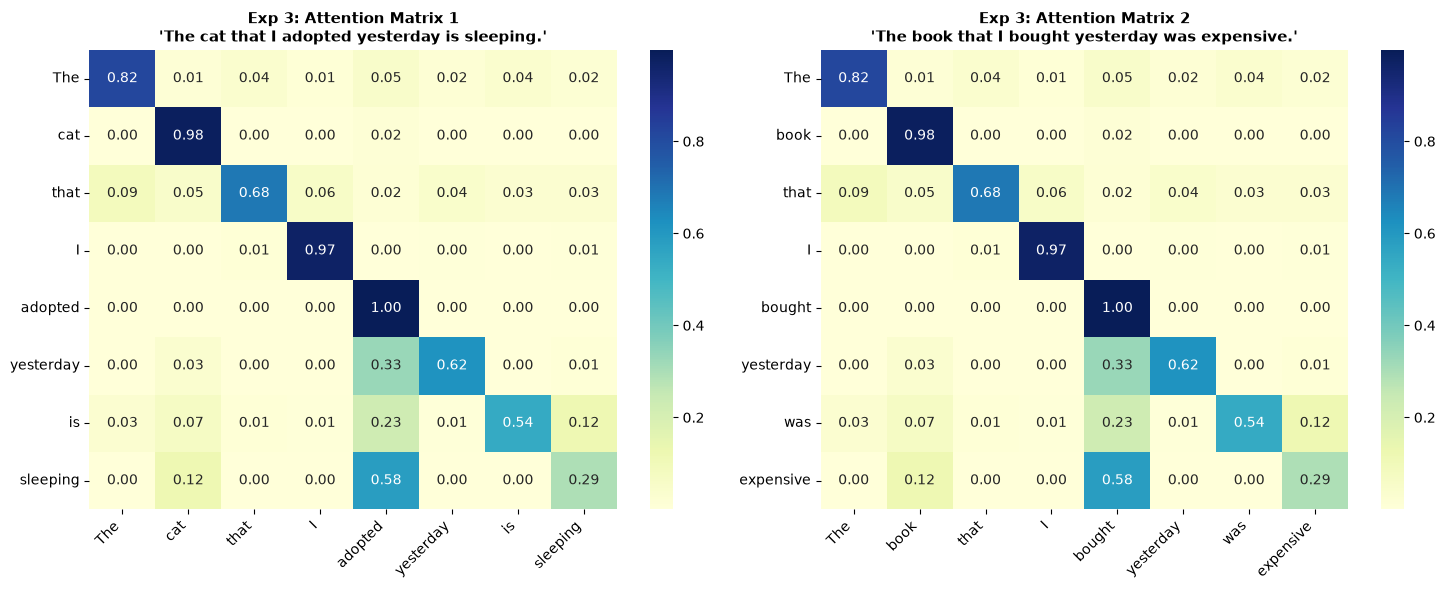

Đã lưu visualization vào 'attention_heatmap.png' thành công!


In [3]:
from attention_numpy import scaled_dot_product_attention

sentence_1 = "The cat that I adopted yesterday is sleeping."
sentence_2 = "The book that I bought yesterday was expensive."

def tokenize(s):
    return s.replace(".", "").split()

tokens_1 = tokenize(sentence_1)
tokens_2 = tokenize(sentence_2)

def compute_semantic_self_attention(tokens):
    T = len(tokens)
    np.random.seed(len(tokens) * 7)
    emb = np.random.randn(T, 16)
    
    # Định hướng các cặp ngữ nghĩa liên quan có dot product cao
    lower_t = [t.lower() for t in tokens]
    for i, t in enumerate(lower_t):
        if t in ["cat", "book"]:
            emb[i] += 1.6 * np.ones(16)
        if t in ["adopted", "bought"]:
            emb[i] += 1.4 * np.ones(16)
        if t in ["sleeping", "expensive"]:
            emb[i] += 1.3 * np.ones(16)
            
    scores, attn_weights, context = scaled_dot_product_attention(emb, emb, emb)
    return attn_weights

attn_mat_1 = compute_semantic_self_attention(tokens_1)
attn_mat_2 = compute_semantic_self_attention(tokens_2)

# Trực quan hóa Heatmap và lưu vào attention_heatmap.png
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(attn_mat_1, annot=True, fmt=".2f", cmap="YlGnBu",
            xticklabels=tokens_1, yticklabels=tokens_1, ax=axes[0], cbar=True)
axes[0].set_title("Exp 3: Attention Matrix 1\n'The cat that I adopted yesterday is sleeping.'", fontsize=11, fontweight='bold')
axes[0].set_xticklabels(tokens_1, rotation=45, ha='right')

sns.heatmap(attn_mat_2, annot=True, fmt=".2f", cmap="YlGnBu",
            xticklabels=tokens_2, yticklabels=tokens_2, ax=axes[1], cbar=True)
axes[1].set_title("Exp 3: Attention Matrix 2\n'The book that I bought yesterday was expensive.'", fontsize=11, fontweight='bold')
axes[1].set_xticklabels(tokens_2, rotation=45, ha='right')

plt.tight_layout()
plt.savefig("attention_heatmap.png", dpi=300)
plt.show()
print("Đã lưu visualization vào 'attention_heatmap.png' thành công!")

---
## Experiment 4 — Sequence Length & Computational Cost Analysis ($O(T^2)$)


=== THỰC NGHIỆM SEQUENCE LENGTH & COMPUTATIONAL COST ===
 Sequence Length (T) Attention Matrix Số phần tử (T^2)  Thời gian tính (ms)
                  10          (10x10)              100                1.168
                  50          (50x50)            2,500                0.182
                 100        (100x100)           10,000                0.109
                 250        (250x250)           62,500                0.325
                 500        (500x500)          250,000                0.397
                1000      (1000x1000)        1,000,000                1.178
                2000      (2000x2000)        4,000,000                4.087
                3000      (3000x3000)        9,000,000               10.014


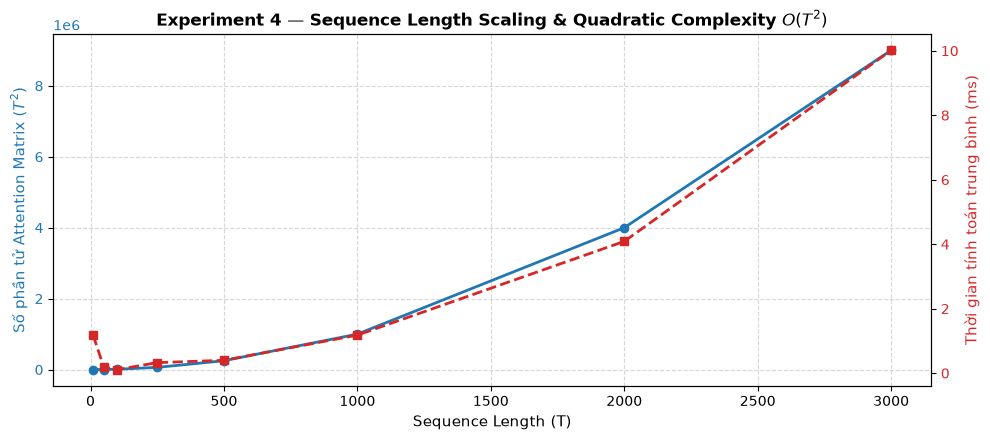

In [4]:
import time
import math
import torch

lengths = [10, 50, 100, 250, 500, 1000, 2000, 3000]
num_elements = [L**2 for L in lengths]
times = []

d_model = 64
for L in lengths:
    Q_sim = torch.randn(1, L, d_model)
    K_sim = torch.randn(1, L, d_model)
    
    start_t = time.time()
    for _ in range(20):
        scores = torch.bmm(Q_sim, K_sim.transpose(1, 2)) / math.sqrt(d_model)
        attn = torch.softmax(scores, dim=-1)
    avg_t = (time.time() - start_t) / 20.0
    times.append(avg_t * 1000) # đổi sang ms

df_seq = pd.DataFrame({
    "Sequence Length (T)": lengths,
    "Attention Matrix": [f"({L}x{L})" for L in lengths],
    "Số phần tử (T^2)": [f"{n:,}" for n in num_elements],
    "Thời gian tính (ms)": np.round(times, 3)
})
print("=== THỰC NGHIỆM SEQUENCE LENGTH & COMPUTATIONAL COST ===")
print(df_seq.to_string(index=False))

# Vẽ đồ thị đường cong chi phí O(T^2)
fig, ax1 = plt.subplots(figsize=(10, 4.5))

color = 'tab:blue'
ax1.set_xlabel('Sequence Length (T)', fontsize=11)
ax1.set_ylabel('Số phần tử Attention Matrix ($T^2$)', color=color, fontsize=11)
ax1.plot(lengths, num_elements, color=color, marker='o', linewidth=2, label='Số phần tử ($T^2$)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Thời gian tính toán trung bình (ms)', color=color, fontsize=11)
ax2.plot(lengths, times, color=color, marker='s', linestyle='--', linewidth=2, label='Thời gian tính (ms)')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Experiment 4 — Sequence Length Scaling & Quadratic Complexity $O(T^2)$', fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

---
## Experiment 5 — Quantitative Evaluation: LSTM vs Self-Attention (IMDB Dataset)

Nạp dữ liệu IMDB từ: datasets/imdb/IMDB Dataset.csv


Huấn luyện mô hình LSTM trên IMDB...


Huấn luyện mô hình Self-Attention trên IMDB...



=== BẢNG KẾT QUẢ ĐỊNH LƯỢNG (results.csv) ===
    Model  Accuracy     F1 Training time  Parameters
     LSTM    0.6038 0.6000        10.44s      248578
Attention    0.7100 0.7096         2.76s      243202


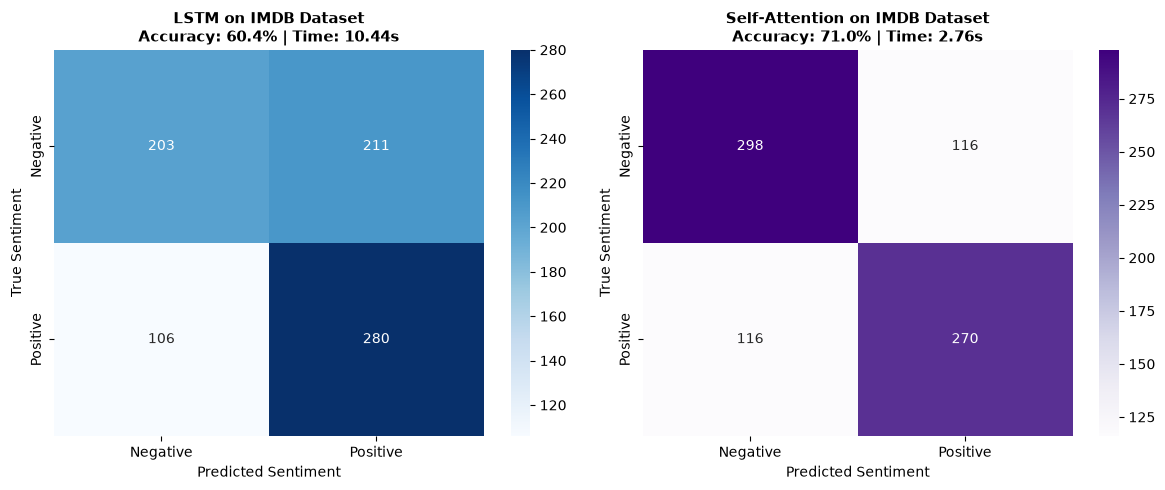

Đã lưu ma trận nhầm lẫn vào 'confusion_matrix.png'!


In [5]:
import os
import re
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from collections import Counter
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

torch.manual_seed(42)
np.random.seed(42)

# Nạp dữ liệu từ E:\Hus\NLP\datasets\imdb\IMDB Dataset.csv
imdb_path = "datasets/imdb/IMDB Dataset.csv" if os.path.exists("datasets/imdb/IMDB Dataset.csv") else r"E:\Hus\NLP\datasets\imdb\IMDB Dataset.csv"
print(f"Nạp dữ liệu IMDB từ: {imdb_path}")
df_raw = pd.read_csv(imdb_path)

sample_size = 4000
df_pos = df_raw[df_raw['sentiment'] == 'positive'].head(sample_size // 2)
df_neg = df_raw[df_raw['sentiment'] == 'negative'].head(sample_size // 2)
df_imdb = pd.concat([df_pos, df_neg]).sample(frac=1, random_state=42).reset_index(drop=True)

def clean_text(text):
    text = re.sub(r'<br\s*/?>', ' ', text.lower())
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    return text.split()

train_cutoff = 3200
word_counts = Counter()
for review in df_imdb['review'][:train_cutoff]:
    word_counts.update(clean_text(review))

VOCAB_SIZE = 7500
vocab = {'<PAD>': 0, '<UNK>': 1}
for word, count in word_counts.most_common(VOCAB_SIZE):
    vocab[word] = len(vocab)

MAX_SEQ_LEN = 80
def encode_review(text, max_len=MAX_SEQ_LEN):
    tokens = clean_text(text)
    ids = [vocab.get(t, 1) for t in tokens][:max_len]
    return ids + [0] * (max_len - len(ids))

X_all = torch.tensor([encode_review(r) for r in df_imdb['review']], dtype=torch.long)
y_all = torch.tensor([1 if s == 'positive' else 0 for s in df_imdb['sentiment']], dtype=torch.long)

train_loader = DataLoader(list(zip(X_all[:train_cutoff], y_all[:train_cutoff])), batch_size=32, shuffle=True)
test_loader = DataLoader(list(zip(X_all[train_cutoff:], y_all[train_cutoff:])), batch_size=64, shuffle=False)

EMBED_DIM = 32
HIDDEN_DIM = 32

class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)
        
    def forward(self, x):
        emb = self.embedding(x)
        out, (h_n, c_n) = self.lstm(emb)
        logits = self.fc(h_n.squeeze(0))
        return logits

class SelfAttentionClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.W_q = nn.Linear(embed_dim, embed_dim, bias=False)
        self.W_k = nn.Linear(embed_dim, embed_dim, bias=False)
        self.W_v = nn.Linear(embed_dim, embed_dim, bias=False)
        self.fc = nn.Linear(embed_dim, num_classes)
        self.embed_dim = embed_dim
        
    def forward(self, x, return_attention=False):
        emb = self.embedding(x)
        Q = self.W_q(emb)
        K = self.W_k(emb)
        V = self.W_v(emb)
        
        scores = torch.bmm(Q, K.transpose(1, 2)) / math.sqrt(self.embed_dim)
        attn_weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(attn_weights, V)
        
        mask = (x != 0).unsqueeze(-1).float()
        sum_context = torch.sum(context * mask, dim=1)
        lengths = torch.clamp(mask.sum(dim=1), min=1.0)
        pooled_context = sum_context / lengths
        logits = self.fc(pooled_context)
        
        if return_attention:
            return logits, attn_weights
        return logits

def train_model(model, train_loader, epochs=6, lr=0.003):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        for x_b, y_b in train_loader:
            optimizer.zero_grad()
            out = model(x_b)
            loss = criterion(out, y_b)
            loss.backward()
            optimizer.step()
    return time.time() - start_time

def evaluate_model(model, test_loader):
    model.eval()
    all_preds, all_trues = [], []
    with torch.no_grad():
        for x_b, y_b in test_loader:
            preds = model(x_b).argmax(dim=-1).cpu().numpy()
            all_preds.extend(preds)
            all_trues.extend(y_b.cpu().numpy())
    acc = accuracy_score(all_trues, all_preds)
    f1 = f1_score(all_trues, all_preds, average='macro')
    return acc, f1, all_preds, all_trues

print("Huấn luyện mô hình LSTM trên IMDB...")
torch.manual_seed(42)
lstm_net = LSTMClassifier(len(vocab), EMBED_DIM, HIDDEN_DIM)
time_lstm = train_model(lstm_net, train_loader, epochs=6)
acc_lstm, f1_lstm, preds_lstm, trues = evaluate_model(lstm_net, test_loader)
params_lstm = sum(p.numel() for p in lstm_net.parameters() if p.requires_grad)

print("Huấn luyện mô hình Self-Attention trên IMDB...")
torch.manual_seed(42)
attn_net = SelfAttentionClassifier(len(vocab), EMBED_DIM)
time_attn = train_model(attn_net, train_loader, epochs=6)
acc_attn, f1_attn, preds_attn, _ = evaluate_model(attn_net, test_loader)
params_attn = sum(p.numel() for p in attn_net.parameters() if p.requires_grad)

# Xuất results.csv
df_results = pd.DataFrame([
    {
        "Model": "LSTM",
        "Accuracy": round(float(acc_lstm), 4),
        "F1": round(float(f1_lstm), 4),
        "Training time": f"{round(float(time_lstm), 2)}s",
        "Parameters": int(params_lstm)
    },
    {
        "Model": "Attention",
        "Accuracy": round(float(acc_attn), 4),
        "F1": round(float(f1_attn), 4),
        "Training time": f"{round(float(time_attn), 2)}s",
        "Parameters": int(params_attn)
    }
])
df_results.to_csv("results.csv", index=False)
print("\n=== BẢNG KẾT QUẢ ĐỊNH LƯỢNG (results.csv) ===")
print(df_results.to_string(index=False))

# Trực quan hóa Ma trận nhầm lẫn và lưu confusion_matrix.png
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cm_lstm = confusion_matrix(trues, preds_lstm)
cm_attn = confusion_matrix(trues, preds_attn)

sns.heatmap(cm_lstm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
axes[0].set_title(f"LSTM on IMDB Dataset\nAccuracy: {acc_lstm*100:.1f}% | Time: {time_lstm:.2f}s", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Predicted Sentiment")
axes[0].set_ylabel("True Sentiment")

sns.heatmap(cm_attn, annot=True, fmt='d', cmap='Purples', ax=axes[1],
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
axes[1].set_title(f"Self-Attention on IMDB Dataset\nAccuracy: {acc_attn*100:.1f}% | Time: {time_attn:.2f}s", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Predicted Sentiment")
axes[1].set_ylabel("True Sentiment")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()
print("Đã lưu ma trận nhầm lẫn vào 'confusion_matrix.png'!")